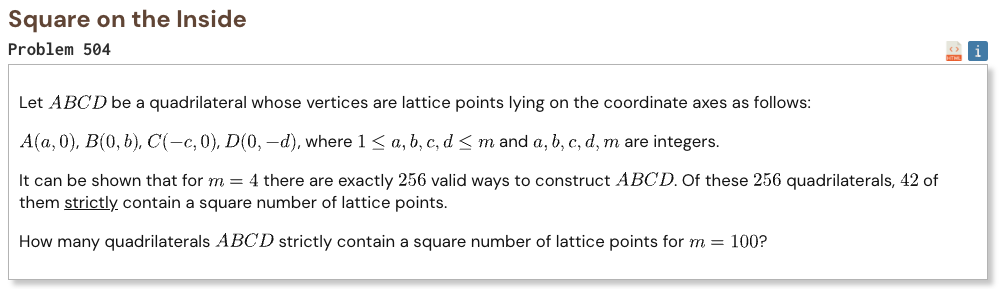

## Initial approach

- use Pick's theorem to calculate the number of lattice points strictly inside each quadrilateral
- the area can be found directly from the four distances on the coordinate axes
- count boundary lattice points with gcd values for the four edges
- precompute all gcd values because the same pairs are used many times
- only check ordered pairs for opposite vertices because swapping them gives the same interior count
- multiply by the corresponding symmetry weight to recover all quadrilaterals
- check whether the interior point count is a perfect square and add the valid cases

In [1]:
%%time

from math import gcd, isqrt

M = 100

gcd_table = [
    [0] * (M + 1)
    for _ in range(M + 1)
]

for a in range(1, M + 1):
    for b in range(1, M + 1):
        gcd_table[a][b] = gcd(a, b)

max_inside = 2 * M * M + 1

squares = {
    x * x
    for x in range(1, isqrt(max_inside) + 1)
}

result = 0

for a in range(1, M + 1):
    for c in range(a, M + 1):
        weight_ac = 1 if a == c else 2
        ac = a + c

        for b in range(1, M + 1):
            first_gcds = (
                gcd_table[a][b]
                + gcd_table[c][b]
            )

            for d in range(b, M + 1):
                boundary = (
                    first_gcds
                    + gcd_table[c][d]
                    + gcd_table[a][d]
                )

                inside = (
                    ac * (b + d)
                    - boundary
                ) // 2 + 1

                if inside in squares:
                    weight_bd = 1 if b == d else 2
                    result += weight_ac * weight_bd

print("Result:", result)

Result: 694687
CPU times: user 4.54 s, sys: 34.6 ms, total: 4.58 s
Wall time: 4.78 s
